## Notebook 2: Dimensionality Reduction & Feature Representation

Welcome! This notebook explores dimensionality reduction techniques to compress high-dimensional astronomical feature spaces. We will use unsupervised methods to project 38 dimensions from Notebook 1 into a lower-dimensional space, making it easier to separate and study Active Galactic Nuclei (AGNs) and Star-Forming Galaxies (SFGs).

---

## Introduction 

### Brief Overview of AGN and SFGs

AGN, or Active Galactic Nuclei, are galaxies that emit a significant fraction of their luminosity from a central supermassive black hole, often overshadowing the regular emissions from the galaxy itself. These intense radiations arise from the gravitational energy released as matter accretes onto the black hole. On the other hand, Star-Forming Galaxies (SFGs) are dominated by star formation processes. Their radio emissions are primarily due to synchrotron radiation produced by relativistic electrons and free-free emissions from HII regions. Differentiating between these two is crucial for understanding galaxy formation and evolution.

### Why Dimensionality Reduction?

Modern astronomical surveys supply a vast number of measured features per source. However, working in high-dimensional spaces introduces the *curse of dimensionality*, where distance metrics lose their meaning and models easily overfit. 

Dimensionality reduction seeks to map the data into a lower-dimensional space while preserving as much meaningful structural information (like variance or local neighborhoods) as possible. This serves as a vital step for feature compression, visualization, and noise filtering before downstream classification.

### Objective

**Objective:** Our primary goal is to use Principal Component Analysis (PCA) to compress high-dimensional feature spaces into orthogonal principal components. We will evaluate how well this lower-dimensional representation separates the physics of AGNs and SFGs, and set the stage for advanced non-linear reduction tasks.

---

### Loading and Preprocessing the Data

In [1]:
import pandas as pd

# Loading the pre-normalized feature matrix and labels saved from Notebook 1
X_scaled = pd.read_csv("data/normalized_mightee.csv")
y_train = pd.read_csv("data/y.csv")["target"]

print(f"Loaded training features shape: {X_scaled.shape}")
print(f"Loaded training target labels shape: {y_train.shape}")

Loaded training features shape: (4121, 38)
Loaded training target labels shape: (4121,)


---

### Linear Reduction: Principal Component Analysis (PCA)

#### Initializing PCA
We initialize PCA to project our features into a 2-dimensional space ($PC_1$ and $PC_2$). This makes it possible to visualize the global variance of our galaxy populations on a standard scatter plot.

In [2]:
from sklearn.decomposition import PCA

n_components = 2
pca = PCA(n_components=n_components, random_state=1912)

#### Fitting and Transforming Data

In [3]:
X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio per component:", pca.explained_variance_ratio_)
print("Total explained variance:", sum(pca.explained_variance_ratio_))

Explained variance ratio per component: [0.15674186 0.11355176]
Total explained variance: 0.2702936145496412


### Visualizing the Principal Component Space

Let us check if projecting our target data down into these two principal components reveals distinct diagnostic structural separations between source types.

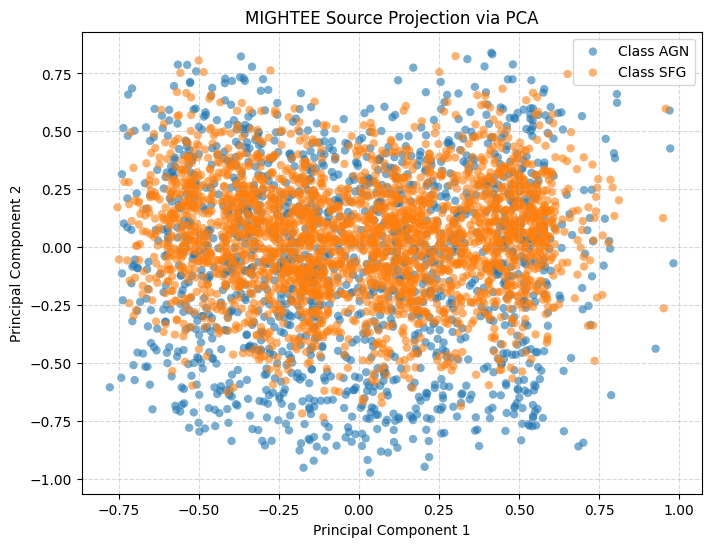

In [5]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 6))

# Color code using the y_train Series loaded directly from your CSV
for label in y_train.unique():
    mask = y_train == label
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], label=f'Class {label}', alpha=0.6, edgecolors='none')

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('MIGHTEE Source Projection via PCA')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

---

### Hackathon Task: Exploring Non-Linear Embeddings

While PCA works brilliantly for extracting global linear variance, complex astronomy data features often exhibit non-linear physical relationships.

#### Your Task:
As a team, research and implement a non-linear dimensionality reduction algorithm to project the MIGHTEE data features (Saved from Notebook 1) down into two/three dimensions. Explore either or both:
1. **t-SNE** 
2. **UMAP** 

#### Deliverables:
* A well-tuned visualization plot showcasing your compressed non-linear features (experiment with hyperparameters like `perplexity` for t-SNE or `n_neighbors` for UMAP).
* Does your non-linear representation outperform linear PCA?
* Save the reduced data